In [2]:
import os, pandas as pd

# read in data
df = pd.read_csv("dataset.csv").drop(columns=["Unnamed: 0"])

# get rid of rows that don't have the data needed
df = df.dropna(subset=["track_name", "artists"])

# find how many genres each track_id has
n_genres = df.groupby("track_id")["track_genre"].nunique()

# keep only tracks with exactly one genre
single = n_genres[n_genres == 1].index
df = df[df["track_id"].isin(single)]

# drop repeats of the same track, then the same name & artist
df = df.drop_duplicates("track_id")
df = df.drop_duplicates(["track_name", "artists"])

# check counts left over
print("after cleaning:", len(df))

after cleaning: 68680


In [3]:
# collect subset of data
counts = df["track_genre"].value_counts()

# get 500 songs each genre that contains at least 500 songs for representative sample
keep = counts[counts >= 500].index
sub = (df[df["track_genre"].isin(keep)]
         .groupby("track_genre").sample(500, random_state=42)
         .reset_index(drop=True))

# double check that counts line up
print(sub["track_genre"].nunique(), "genres,", len(sub), "songs")

78 genres, 39000 songs


In [4]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# duration created outliers, so log them instead of removing long songs
sub["log_duration"] = np.log1p(sub["duration_ms"])

# select features
features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo", "log_duration"]

# put all features on same scale
X = StandardScaler().fit_transform(sub[features])

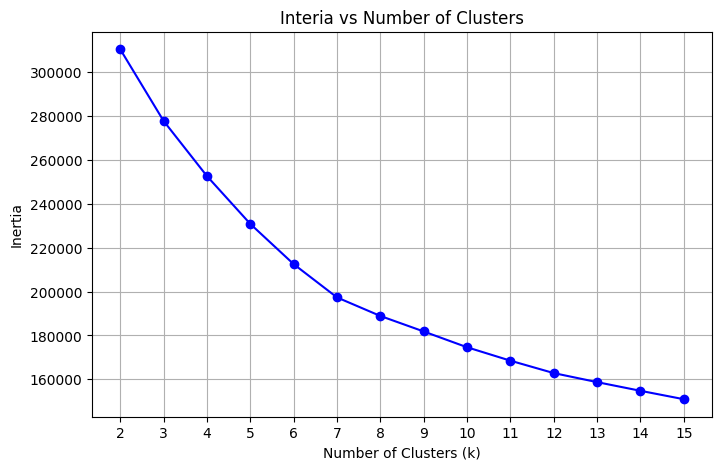

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# set up list
inertia_values = []

# loop through each k and find each inertia, record value in list
for k in range(2, 16):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

# plot the inertia values
plt.figure(figsize=(8, 5))
plt.plot(range(2, 16), inertia_values, marker='o', linestyle='-', color='b')
plt.title('Interia vs Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(2, 16))
plt.grid(True)
plt.show()

In [6]:
# deciding between k=7 or k=8, so look at clusters

for k_try in [7, 8]:
    m = KMeans(n_clusters=k_try, n_init=10, random_state=42).fit(X)
    tmp = sub.copy()
    tmp["cluster"] = m.labels_
    print(f"k={k_try}")
    print(tmp["cluster"].value_counts().sort_index().to_string())
    print(tmp.groupby("cluster")[features].mean().round(2))
    print((tmp.groupby("cluster")["duration_ms"].mean() / 60000).round(1).to_string())   # minutes to increase clarity

# on graph k=7 looks better but more meaningful clusters with k=8
# chose k=8

k=7
cluster
0     8470
1     4891
2    11005
3     2908
4     3556
5      516
6     7654
         danceability  energy  loudness  speechiness  acousticness  \
cluster                                                              
0                0.47    0.82     -5.40         0.09          0.07   
1                0.57    0.75     -8.53         0.07          0.10   
2                0.70    0.72     -6.73         0.10          0.24   
3                0.51    0.75     -7.12         0.09          0.31   
4                0.33    0.16    -21.59         0.05          0.86   
5                0.57    0.67    -11.61         0.86          0.76   
6                0.53    0.37    -10.75         0.06          0.70   

         instrumentalness  liveness  valence   tempo  log_duration  
cluster                                                             
0                    0.05      0.20     0.36  138.70         12.33  
1                    0.79      0.17     0.34  127.93         12.49  
2   

In [7]:
# moved forward with k=8, review values
# check how many songs in each cluster add up to total number of songs
K = 8
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
sub["cluster"] = km.labels_
print(sub["cluster"].value_counts().sort_index())

cluster
0    4771
1    8010
2    3517
3    9517
4     465
5    2509
6    7367
7    2844
Name: count, dtype: int64


In [12]:
import numpy as np

# pick out elements in cluster - top genres and songs
# use top genres to identify what cluster represents
# verify with songs close to cluster center
for cl in range(K):
    members = sub[sub["cluster"] == cl]
    print(f"\nCluster {cl}: {len(members)} songs")
    print("Top genres:", members["track_genre"].value_counts(normalize=True).head(6).round(2).to_dict())
    idx = np.where(sub["cluster"] == cl)[0]
    d = np.linalg.norm(X[idx] - km.cluster_centers_[cl], axis=1)
    print(sub.iloc[idx[np.argsort(d)[:2]]][["track_name", "artists", "track_genre"]].to_string(header=False))


Cluster 0: 4771 songs
Top genres: {'minimal-techno': 0.09, 'detroit-techno': 0.08, 'trance': 0.06, 'chicago-house': 0.05, 'idm': 0.05, 'grindcore': 0.04}
2289   Temple of New Jerusalem  Therion     black-metal
24618                EASY PREY  Moderat  minimal-techno

Cluster 1: 8010 songs
Top genres: {'metalcore': 0.05, 'heavy-metal': 0.04, 'grunge': 0.04, 'hardstyle': 0.04, 'death-metal': 0.04, 'industrial': 0.03}
16212                          Ghost                                                                                              Badflower             grunge
28676  Instagram - Bassjackers Remix  Dimitri Vegas & Like Mike;David Guetta;Daddy Yankee;Afro Bros;Natti Natasha;Dimitri Vegas;Bassjackers  progressive-house

Cluster 2: 3517 songs
Top genres: {'sleep': 0.11, 'new-age': 0.11, 'ambient': 0.1, 'classical': 0.1, 'piano': 0.08, 'disney': 0.06}
27413  Hayat Ağacı Süiti, Op. 100: III. Ece  Fazıl Say;Jamal Aliyev    piano
25033           The Days That'll Never Come          

In [11]:
# make table defining clusters based off information above

import pandas as pd

names = {
    0: "Energetic electronic instrumentals",
    1: "Loud, fast, intense",
    2: "Quiet, calm instrumentals",
    3: "Upbeat, danceable, feel-good",
    4: "Spoken word and comedy",
    5: "Rhythmic, vocal-heavy",
    6: "Soft acoustic vocal",
    7: "Live-sounding, energetic",
}

cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
        "instrumentalness", "liveness", "valence", "tempo"]

table = sub.groupby("cluster")[cols].mean()
table.insert(0, "Songs", sub["cluster"].value_counts().sort_index())
table["Avg length (min)"] = sub.groupby("cluster")["duration_ms"].mean() / 60000
table.insert(0, "Profile", pd.Series(names))
table.index.name = "Cluster"
table = table.rename(columns=lambda c: c.capitalize() if c != "Avg length (min)" else c)
table = table.rename(columns={"Loudness": "Loudness (dB)", "Tempo": "Tempo (BPM)"})

styled = (table.style
    .format({"Songs": "{:,}", "Loudness (dB)": "{:.1f}", "Tempo (BPM)": "{:.0f}",
             "Avg length (min)": "{:.1f}"}, precision=2)
    .set_caption("Average audio features by cluster")
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]},
                       {"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold")]}]))
styled

,Profile,Songs,Danceability,Energy,Loudness (dB),Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo (BPM),Avg length (min)
Cluster,,,,,,,,,,,,
0,Energetic electronic instrumentals,"4,771",0.57,0.75,-8.5,0.07,0.10,0.79,0.17,0.33,128,5.0
1,"Loud, fast, intense","8,010",0.46,0.82,-5.4,0.08,0.07,0.05,0.20,0.34,138,4.0
2,"Quiet, calm instrumentals","3,517",0.33,0.16,-21.6,0.05,0.86,0.79,0.16,0.17,102,3.6
3,"Upbeat, danceable, feel-good","9,517",0.68,0.74,-6.6,0.06,0.24,0.03,0.17,0.74,121,3.6
4,Spoken word and comedy,465,0.56,0.69,-11.5,0.89,0.79,0.00,0.72,0.42,98,3.6
5,"Rhythmic, vocal-heavy","2,509",0.72,0.66,-7.5,0.31,0.26,0.04,0.18,0.57,120,3.0
6,Soft acoustic vocal,"7,367",0.53,0.37,-10.8,0.05,0.70,0.06,0.16,0.39,113,3.6
7,"Live-sounding, energetic","2,844",0.51,0.75,-7.1,0.08,0.31,0.08,0.76,0.50,124,4.0
